nov 24th, rob said use option 2

In [22]:
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
import pandas as pd
import boule as bl
import verde as vd
import harmonica as hm
from numba import njit

In [23]:
df = pd.read_csv('..\\..\\created_data\\mcs\\02_nov23_FA_toc_tos_interp.csv', skiprows=1,
                 names=['x', 'y', 'long', 'lat', 'z_sed', 'z_crust', 'depth_m', 'depth_km', 'FA'])

print(df.head())

          x          y        long        lat     z_sed   z_crust  \
0  193122.0  5277091.0 -127.080767  47.574574  3.387986  4.506494   
1  193116.0  5277093.0 -127.080848  47.574589  3.387924  4.508189   
2  193110.0  5277095.0 -127.080929  47.574604  3.387768  4.510482   
3  193104.0  5277097.0 -127.081010  47.574619  3.387614  4.516385   
4  193098.0  5277099.0 -127.081091  47.574634  3.387520  4.525014   

       depth_m  depth_km        FA  
0  3659.497500  3.659498 -8.343770  
1  3661.208000  3.661208 -8.341758  
2  3663.540000  3.663540 -8.339742  
3  3669.481501  3.669482 -8.337727  
4  3678.134000  3.678134 -8.335712  


# tesseroid time!
Now we are going to plot the gravity as a tesseroid (6 bounds: west, east, south, north, bottom, top)

GRS80 (Geodetic Reference System 1980) vs WGS84 (World Geodetic System 1984) --> '...if you're using GPS coordinates or anything referenced to satellite positioning, you're technically in WGS84; if you're doing pure geodetic/gravity theory work, GRS80 is the traditional standard.'

In [24]:
mean_radius = bl.WGS84.mean_radius  # from boule, earth radius for an ellipsoid

## (1)
"Decimate to one point per tesseroid. Points are ~6 m apart (utm vals) but a tesseroid is ~1 km wide. Bin them so each tesseroid gets exactly one point and neighbors tile without overlapping."
- binning groups continous data into discrete intervals --> 0.01 degrees by 0.01 degrees

In [20]:
region=df['long'].min(), df['long'].max(), df['lat'].min(), df['lat'].max()

# number of pnts in each S-N and W-E direction, adjust based on data density
spacing=0.01 # degrees, tesseroid width

turn all coordinates into an integer ie. -127.4537 / 0.01 = -12745.37 and its floor is -12746

In [26]:
df['long_floor'] = np.floor(df['long'] / spacing).astype(int)
df['lat_floor'] = np.floor(df['lat'] / spacing).astype(int)

groupby will collect all points in 1 cell and uses .agg to replace them with the mean FA, TOS and TOC, so the result has 1 row per cell

In [28]:
binned = (df.groupby(['long_floor', 'lat_floor'], as_index=False)
            .agg(FA=('FA', 'mean'), tos=('z_sed', 'mean'), toc=('z_crust', 'mean')))

In [29]:
print(binned)

    long_floor  lat_floor        FA       tos       toc
0       -12778       4771  0.260859  3.579623  3.947144
1       -12777       4771  0.260960  3.580763  4.090257
2       -12776       4771  0.261098  3.580208  4.130884
3       -12775       4770  0.310812  3.577885  4.158206
4       -12775       4771  0.270205  3.579012  4.124098
..         ...        ...       ...       ...       ...
79      -12712       4758 -7.502915  3.401987  4.554855
80      -12711       4757 -7.784503  3.397915  4.525698
81      -12711       4758 -7.661755  3.404374  4.554771
82      -12710       4757 -7.993951  3.393908  4.459741
83      -12709       4757 -8.230649  3.390683  4.506515

[84 rows x 5 columns]


"In the model, each cell becomes a vertical stack of tesseroids, one per layer (water, sed, crust)."

In [31]:
# bin centers
binned['long'] = (binned['long_floor'] + 0.5) * spacing
binned['lat'] = (binned['lat_floor'] + 0.5) * spacing
n = len(binned)
print(f'{n} tesseroids per layer, so {n*3} tesseroids total in the model')

84 tesseroids per layer, so 252 tesseroids total in the model


### option 2: hm.tesseroid_gravity: forward model that computes unknown gravity from a physical model

[vd.grid_coords](https://www.fatiando.org/verde/latest/api/generated/verde.grid_coordinates.html#verde-grid-coordinates) 
and [tutorial](https://www.fatiando.org/verde/dev/tutorials/grid_coordinates.html) --> generates raw coordinate values, whereas [vd.make_xarray_grid](https://www.fatiando.org/verde/latest/api/generated/verde.make_xarray_grid.html) takes arrays and packages them into a dataset

[hm.tesseroid_gravity](https://www.fatiando.org/harmonica/latest/api/generated/harmonica.tesseroid_gravity.html) --> from hm tesseroid example but takes too long for all the data

field options:
- grav potential: potential [J/kg]
- downward acc: g_z [mGal --> 10e-5 m/s^2]

In [9]:
bottom = ellipsoid.mean_radius - 10e3
top = ellipsoid.mean_radius

In [10]:
@njit
def density(radius):
    """Linear density function"""
    top = mean_radius
    bottom = mean_radius - 10e3
    density_top = 2670
    density_bottom = 3000
    slope = (density_top - density_bottom) / (top - bottom)
    return slope * (radius - bottom) + density_bottom

extra coords creates an extra coordinate that the same shape as the coordinate grid with a constant value (in this case, radius)

In [12]:
coords = vd.grid_coordinates(
    region=region,
    spacing=spacing,
    extra_coords=mean_radius)

# tesseroid = ([df['FA'][0], region[1] - 3, region[2] + 1, region[3] - 1, 
#                 bottom, top])

# gravity = hm.tesseroid_gravity(coords, tesseroid, density, field='g_z')

In [13]:

lon = df['long'].values
lat = df['lat'].values
n = len(df)

# half-width of each tesseroid in degrees
dlon = dlat = spacing / 2

tesseroids = np.column_stack([
    lon - dlon, lon + dlon,
    lat - dlat, lat + dlat,
    np.full(n, bottom),
    np.full(n, top),
])

# observation points: same lon/lat, at a radius (add station elevation if you have it)
coords = (lon, lat, np.full(n, mean_radius))

gravity = hm.tesseroid_gravity(coords, tesseroids, density, field='g_z')


In [ ]:
# grid = vd.make_xarray_grid(coords, gravity, data_names='gravity', extra_coords_names='extra')

In [14]:
df['gravity'] = gravity
df['residual'] = df['FA'] - df['gravity']

# print(df['gravity'].head())
# print(df['residual'].head())

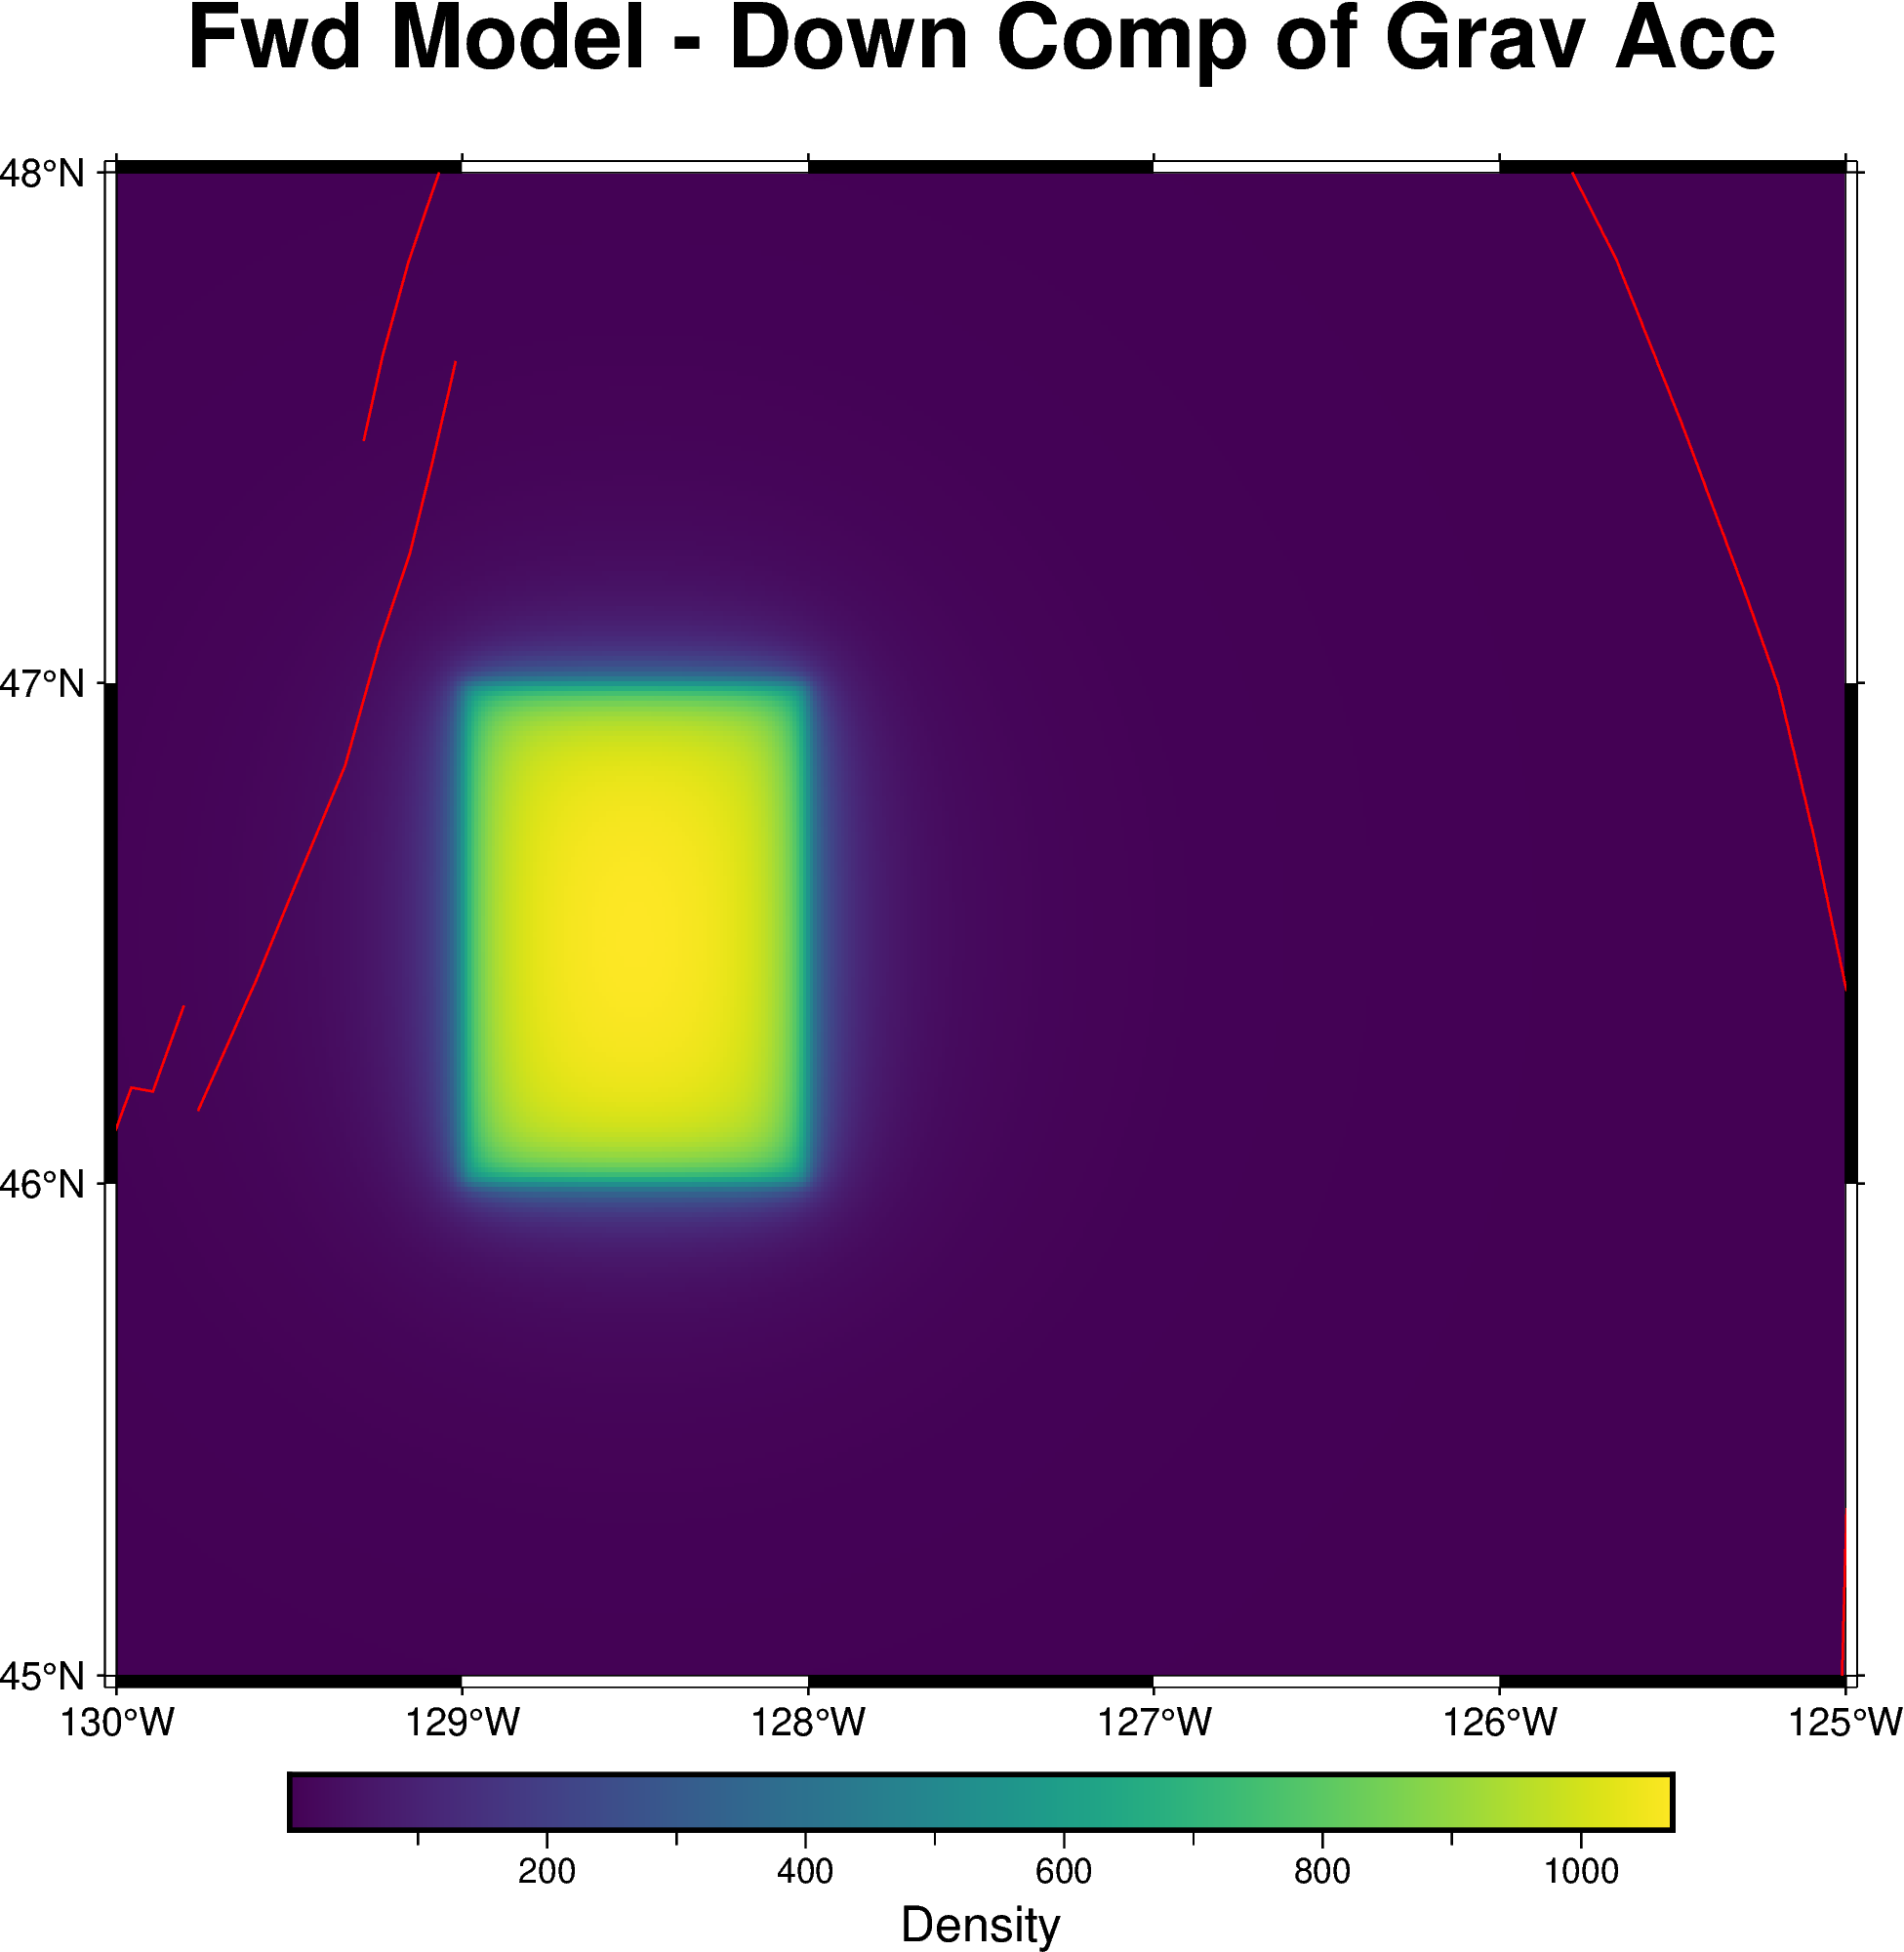

In [ ]:
fig = pygmt.Figure()
title = 'Fwd Model - Down Comp of Grav Acc'
# with pygmt.config(FONT_TITLE='22p'):
#    fig.grdimage(
#       region=region,
#       projection='M15c',
#       grid=grid.gravity,
#       frame=['a', f'+t{title}'],
#       cmap='viridis',
#    )

fig.plot()

fig.plot(data='..\\..\\data\\Plate_Boundaries.shp\\Plate_Boundaries.shp', pen='0.5p,red')
fig.coast(land='green', transparency=50, shorelines='0.5p,darkgreen')

fig.colorbar(cmap=True, frame=['a200f100', 'x+lDensity'])

# fig.savefig(f'..\\..\\figures\\jdf_grav_sept8\\fwd_model_acc_sp{spacing}.png', dpi=400, crop='0.5c')  # crop to put whitespace around when i save it
fig.show()